# 04b · Modelamiento de Ignacio Silva: duración y escalado robusto

**Responsable:** Ignacio Silva · **Etapas CRISP-DM:** Modeling y Evaluation.

**Pregunta:** ¿cambia el desempeño de los modelos al comprimir la cola de duración con `log1p`, usar escalado robusto o combinar ambas decisiones? Se mantiene el protocolo común: misma fuente, misma partición por canción, referencia mediana, Ridge, árbol, métricas fuera de muestra, errores por rangos y K-Means/PCA.

El experimento cambia únicamente la preparación numérica entre las cuatro variantes declaradas; conserva los mismos predictores, IDs, modelos candidatos y semilla. Los resultados describen una muestra histórica artificialmente balanceada por género y no predicen éxito futuro.


## 1. Fuente, preparación y controles

La EP1 halló 89.740 canciones únicas, 10,47% con popularidad cero y 3,48% con popularidad ≥ 70.
También encontró asociaciones acústicas individuales débiles, redundancia entre `energy` y
`loudness`, y una muestra artificialmente balanceada por género. Por eso se conserva una referencia
simple, se analizan errores por rangos y se evita extrapolar la prevalencia al catálogo completo.
Se regenera el procesado desde el CSV original con las reglas ya aprobadas, sin editar la fuente.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)
from sklearn.tree import DecisionTreeRegressor

from spotify_popularity.analysis.exploratory import validate_processed_dataset
from spotify_popularity.config import PROJECT_PATHS
from spotify_popularity.data.loader import load_raw_dataset
from spotify_popularity.data.preparation import prepare_modeling_dataset
from spotify_popularity.data.provenance import sha256_file
from spotify_popularity.modeling.protocol import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    SEED,
    GenreBinarizer,
    genre_only_pipeline,
    regression_metrics,
    split_track_ids,
    top_decile_kpi,
)

source_hash = sha256_file(PROJECT_PATHS.raw_dataset)
data, preparation = prepare_modeling_dataset(load_raw_dataset())
controls = validate_processed_dataset(data)
assert controls["shape"] == (89_740, 20)
assert controls["missing_cells"] == 0
assert controls["duplicate_track_ids"] == 0
assert controls["non_positive_durations"] == 0
assert controls["empty_genres"] == 0
assert data["popularity"].between(0, 100).all()
print(f"Fuente SHA-256: {source_hash}")
print(f"scikit-learn/pandas: {sklearn.__version__} / {pd.__version__}")
print(f"Preparación: {preparation}")
display(pd.Series(controls, name="valor").to_frame())

# Variantes predefinidas: diseño factorial 2×2 de transformación de duración y escalado.
TREATMENTS = {
    "estándar": (False, "standard"),
    "log_duración": (True, "standard"),
    "robusto": (False, "robust"),
    "log_duración_robusto": (True, "robust"),
}

def ignacio_pipeline(estimator, treatment):
    """Transforma y escala dentro del pipeline, ajustando solo sobre el conjunto de fit."""
    log_duration, scaler_name = TREATMENTS[treatment]
    scaler_factory = RobustScaler if scaler_name == "robust" else StandardScaler
    transformers = []
    if log_duration:
        duration_pipeline = Pipeline([
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", scaler_factory()),
        ])
        other_numeric = [column for column in NUMERIC_FEATURES if column != "duration_ms"]
        transformers.extend([
            ("duration", duration_pipeline, ["duration_ms"]),
            ("numeric", scaler_factory(), other_numeric),
        ])
    else:
        transformers.append(("numeric", scaler_factory(), list(NUMERIC_FEATURES)))
    transformers.extend([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), list(CATEGORICAL_FEATURES)),
        ("genres", GenreBinarizer(), ["track_genres"]),
    ])
    preprocessing = ColumnTransformer(transformers, remainder="drop", sparse_threshold=1.0)
    return Pipeline([("preprocessing", preprocessing), ("model", estimator)])


Fuente SHA-256: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
scikit-learn/pandas: 1.9.0 / 2.3.3
Preparación: PreparationSummary(input_rows=114000, invalid_rows_removed=1, output_rows=89740, repeated_track_ids_consolidated=24259)


,valor
shape,"(89740, 20)"
missing_cells,0
unique_track_ids,89740
duplicate_track_ids,0
non_positive_durations,0
empty_genres,0


## 2. Partición común y prevención de fuga

La unidad es `track_id`, ya deduplicada. Se ordenan los IDs antes de una separación 80/20 con
semilla 42; del entrenamiento se aparta 20% para validación. El conjunto de prueba queda reservado
hasta que se fijan parámetros y candidato recomendado. `track_id`, artistas, títulos y la variable
objetivo no entran en la matriz de predictores. La escala y los codificadores se ajustan dentro de
cada pipeline usando solo las filas disponibles para ese ajuste.

In [2]:
split = split_track_ids(data)
feature_columns = list(NUMERIC_FEATURES) + list(CATEGORICAL_FEATURES) + ["track_genres"]
indexed = data.set_index("track_id", drop=False)
fit_data = indexed.loc[list(split.fit_ids)]
validation_data = indexed.loc[list(split.validation_ids)]
train_data = indexed.loc[list(split.train_ids)]
test_data = indexed.loc[list(split.test_ids)]

X_fit, y_fit = fit_data[feature_columns], fit_data["popularity"]
X_validation, y_validation = validation_data[feature_columns], validation_data["popularity"]
X_train, y_train = train_data[feature_columns], train_data["popularity"]
X_test, y_test = test_data[feature_columns], test_data["popularity"]
assert not set(split.train_ids).intersection(split.test_ids)
assert set(split.fit_ids).union(split.validation_ids) == set(split.train_ids)
assert len(split.train_ids) == 71_792 and len(split.test_ids) == 17_948

print(f"Semilla: {SEED}")
print(
    f"Ajuste: {len(X_fit):,}; validación: {len(X_validation):,}; "
    f"entrenamiento total: {len(X_train):,}; prueba: {len(X_test):,}"
)
print(f"SHA-256 de IDs de prueba ordenados: {split.test_sha256}")
display(
    pd.DataFrame(
        {
            "partición": ["ajuste", "validación", "prueba"],
            "canciones": [len(X_fit), len(X_validation), len(X_test)],
            "popularidad_media": [y_fit.mean(), y_validation.mean(), y_test.mean()],
            "proporción_70_o_más": [
                y_fit.ge(70).mean(),
                y_validation.ge(70).mean(),
                y_test.ge(70).mean(),
            ],
        }
    ).round(3)
)

Semilla: 42
Ajuste: 57,433; validación: 14,359; entrenamiento total: 71,792; prueba: 17,948
SHA-256 de IDs de prueba ordenados: 7270ff57b6fb81215fba2f834942d194183e3854ccac935a65e5a03f7888b318


,partición,canciones,popularidad_media,proporción_70_o_más
0,ajuste,57433,33.138,0.035
1,validación,14359,33.174,0.033
2,prueba,17948,33.411,0.036


## 3. Algoritmos y selección con validación

`popularity` es una variable numérica y se aborda como regresión. La referencia predice la mediana del entrenamiento. Ridge regulariza una combinación lineal; el árbol puede capturar umbrales e interacciones, aunque puede sobreajustar. Se comparan los `alpha` 0,1; 1; 10; 100 y árboles de profundidad 5, 10 o 15 con hojas mínimas de 20 o 100. Para cada tratamiento numérico se seleccionan parámetros por MAE de validación y se desempata con RMSE y complejidad. Las cuatro variantes conservan filas, predictores y candidatos; solo cambian duración y escalado.


In [3]:
ridge_grid = [{"alpha": alpha} for alpha in (0.1, 1.0, 10.0, 100.0)]
tree_grid = [
    {"max_depth": depth, "min_samples_leaf": leaf} for depth in (5, 10, 15) for leaf in (20, 100)
]


def estimator_for(model_name, parameters):
    if model_name == "Ridge":
        return Ridge(**parameters)
    return DecisionTreeRegressor(random_state=SEED, **parameters)


reference_validation = DummyRegressor(strategy="median").fit(X_fit, y_fit)
reference_validation_metrics = regression_metrics(
    y_validation, reference_validation.predict(X_validation)
)
validation_rows = []
for variant in TREATMENTS:
    for model_name, parameter_grid in (("Ridge", ridge_grid), ("Árbol", tree_grid)):
        for parameters in parameter_grid:
            estimator_name = "Ridge" if model_name == "Ridge" else "Árbol"
            pipeline = ignacio_pipeline(estimator_for(estimator_name, parameters), variant)
            pipeline.fit(X_fit, y_fit)
            scores = regression_metrics(y_validation, pipeline.predict(X_validation))
            complexity = (
                -parameters["alpha"]
                if model_name == "Ridge"
                else parameters["max_depth"] * 1000 - parameters["min_samples_leaf"]
            )
            validation_rows.append(
                {
                    "variante": variant,
                    "modelo": model_name,
                    "parámetros": parameters,
                    "complejidad": complexity,
                    **scores,
                }
            )

validation = pd.DataFrame(validation_rows)
selected = (
    validation.sort_values(["MAE", "RMSE", "complejidad"])
    .groupby(["variante", "modelo"], sort=False)
    .head(1)
    .sort_values(["variante", "MAE"])
    .reset_index(drop=True)
)
print("Referencia en validación:", reference_validation_metrics)
display(validation.sort_values(["variante", "modelo", "MAE"]).round(3))
print("Configuraciones seleccionadas usando solo validación:")
display(selected.round(3))

best_candidate = selected.sort_values(["MAE", "RMSE", "complejidad"]).iloc[0]
recommended_before_test = (
    f"{best_candidate['modelo']} / {best_candidate['variante']}"
    if best_candidate["MAE"] < reference_validation_metrics["MAE"]
    else "Referencia"
)
print("Candidato recomendado antes de abrir la prueba:", recommended_before_test)

Referencia en validación: {'MAE': 17.207535343686885, 'RMSE': 20.535261977137537, 'R2': -7.188898482390904e-05}


,variante,modelo,parámetros,complejidad,MAE,RMSE,R2
0,estándar,Ridge,{'alpha': 0.1},-0.1,11.786,16.430,0.360
1,estándar,Ridge,{'alpha': 1.0},-1.0,11.788,16.430,0.360
2,estándar,Ridge,{'alpha': 10.0},-10.0,11.818,16.435,0.359
3,estándar,Ridge,{'alpha': 100.0},-100.0,12.169,16.574,0.349
8,estándar,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
9,estándar,Árbol,"{'max_depth': 15, 'min_samples_leaf': 100}",14900.0,14.442,18.360,0.201
6,estándar,Árbol,"{'max_depth': 10, 'min_samples_leaf': 20}",9980.0,15.088,18.827,0.159
7,estándar,Árbol,"{'max_depth': 10, 'min_samples_leaf': 100}",9900.0,15.109,18.852,0.157
4,estándar,Árbol,"{'max_depth': 5, 'min_samples_leaf': 20}",4980.0,15.896,19.496,0.099
5,estándar,Árbol,"{'max_depth': 5, 'min_samples_leaf': 100}",4900.0,15.898,19.496,0.099


Configuraciones seleccionadas usando solo validación:


,variante,modelo,parámetros,complejidad,MAE,RMSE,R2
0,estándar,Ridge,{'alpha': 0.1},-0.1,11.786,16.430,0.360
1,estándar,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
2,log_duración,Ridge,{'alpha': 0.1},-0.1,11.788,16.430,0.360
3,log_duración,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
4,log_duración_robusto,Ridge,{'alpha': 0.1},-0.1,11.788,16.430,0.360
5,log_duración_robusto,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205
6,robusto,Ridge,{'alpha': 0.1},-0.1,11.786,16.430,0.360
7,robusto,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14980.0,14.393,18.312,0.205


Candidato recomendado antes de abrir la prueba: Ridge / estándar


## 4. Evaluación final en la prueba reservada

Se reajustan las ocho configuraciones seleccionadas —Ridge y árbol para cada uno de los cuatro tratamientos— con las 71.792 canciones de entrenamiento. La prueba se consulta una vez para las variantes declaradas de antemano. MAE y RMSE se expresan en puntos de popularidad; R² compara el error cuadrático con una constante igual a la media observada en la prueba y puede ser negativo. La diferencia de MAE respecto de la referencia mediana indica si una configuración aporta evidencia predictiva en esta muestra.


,variante,modelo,parámetros,MAE,RMSE,R2,mejora_MAE_puntos,mejora_MAE_pct
1,estándar,Ridge,{'alpha': 0.1},11.915,16.643,0.348,5.335,30.929
2,estándar,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.508,18.460,0.198,2.742,15.898
3,log_duración,Ridge,{'alpha': 0.1},11.914,16.643,0.348,5.336,30.931
4,log_duración,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.508,18.460,0.198,2.742,15.898
5,log_duración_robusto,Ridge,{'alpha': 0.1},11.914,16.643,0.348,5.336,30.931
6,log_duración_robusto,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.507,18.460,0.198,2.743,15.901
0,referencia,Referencia,mediana,17.250,20.612,-0.000,0.000,0.000
7,robusto,Ridge,{'alpha': 0.1},11.915,16.643,0.348,5.335,30.929
8,robusto,Árbol,"{'max_depth': 15, 'min_samples_leaf': 20}",14.507,18.460,0.198,2.743,15.901


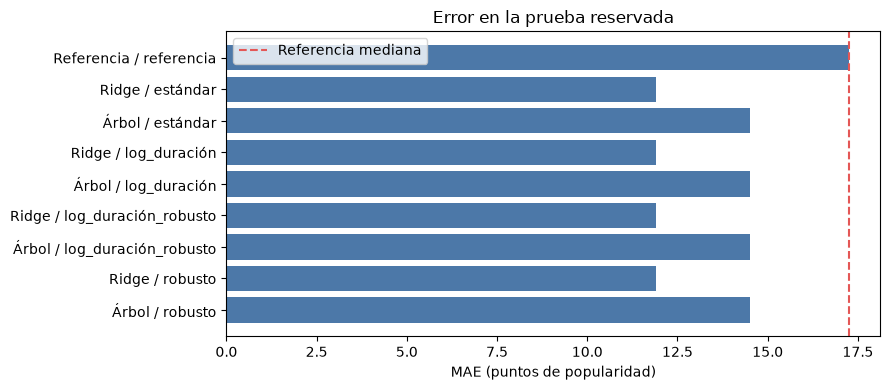

In [4]:
reference = DummyRegressor(strategy="median").fit(X_train, y_train)
predictions = {"Referencia": reference.predict(X_test)}
test_rows = [
    {
        "variante": "referencia",
        "modelo": "Referencia",
        "parámetros": "mediana",
        **regression_metrics(y_test, predictions["Referencia"]),
    }
]

for row in selected.itertuples(index=False):
    name = f"{row.modelo} / {row.variante}"
    pipeline = ignacio_pipeline(estimator_for(row.modelo, row.parámetros), row.variante)
    pipeline.fit(X_train, y_train)
    predictions[name] = pipeline.predict(X_test)
    test_rows.append(
        {
            "variante": row.variante,
            "modelo": row.modelo,
            "parámetros": row.parámetros,
            **regression_metrics(y_test, predictions[name]),
        }
    )

test_scores = pd.DataFrame(test_rows)
baseline_mae = test_scores.loc[test_scores["modelo"].eq("Referencia"), "MAE"].iloc[0]
test_scores["mejora_MAE_puntos"] = baseline_mae - test_scores["MAE"]
test_scores["mejora_MAE_pct"] = 100 * test_scores["mejora_MAE_puntos"] / baseline_mae
display(test_scores.sort_values(["variante", "MAE"]).round(3))

plot_scores = test_scores.copy()
plot_scores["etiqueta"] = plot_scores["modelo"] + " / " + plot_scores["variante"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(plot_scores["etiqueta"], plot_scores["MAE"], color="#4C78A8")
ax.axvline(baseline_mae, color="#E45756", linestyle="--", label="Referencia mediana")
ax.set(xlabel="MAE (puntos de popularidad)", title="Error en la prueba reservada")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04b_ignacio_model_mae.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

### Experimento de Ignacio: duración y escalado

Se comparan cuatro variantes: (1) `StandardScaler` como tratamiento estándar; (2) `log1p(duration_ms)` y escalado estándar; (3) `RobustScaler` para las variables numéricas; y (4) `log1p(duration_ms)` con `RobustScaler`. Esto permite comparar cada decisión por separado y su combinación. Las transformaciones se ejecutan dentro de cada pipeline y se ajustan solo con el conjunto de entrenamiento de cada evaluación. En Ridge, cambiar de escala modifica la penalización efectiva; en un árbol, el escalado por sí solo conserva el orden de los valores, pero `log1p` puede cambiar dónde se sitúan los cortes de duración. La selección usa MAE de validación, con RMSE y complejidad para desempatar.


In [5]:
treatment_rows = []
for treatment in TREATMENTS:
    val_winners = selected.loc[selected["variante"].eq(treatment)].sort_values(
        ["MAE", "RMSE", "complejidad"]
    )
    test_treatment = test_scores.loc[test_scores["variante"].eq(treatment)].sort_values("MAE")
    if val_winners.empty or test_treatment.empty:
        continue
    chosen = val_winners.iloc[0]
    chosen_test = test_scores.loc[
        test_scores["modelo"].eq(chosen["modelo"]) & test_scores["variante"].eq(treatment)
    ].iloc[0]
    descriptive_test_winner = test_treatment.iloc[0]
    treatment_rows.append({
        "tratamiento": treatment,
        "modelo_elegido_validación": chosen["modelo"],
        "parámetros": chosen["parámetros"],
        "MAE_validación": chosen["MAE"],
        "MAE_prueba_del_modelo_elegido": chosen_test["MAE"],
        "mejor_MAE_prueba_solo_descriptivo": descriptive_test_winner["MAE"],
        "modelo_menor_MAE_prueba_solo_descriptivo": descriptive_test_winner["modelo"],
    })
treatment_comparison = pd.DataFrame(treatment_rows)
print("Comparación por modelo elegido en validación (prueba solo para evaluación):")
display(treatment_comparison.round(3))


Comparación por modelo elegido en validación (prueba solo para evaluación):


,tratamiento,modelo_elegido_validación,parámetros,MAE_validación,MAE_prueba_del_modelo_elegido,mejor_MAE_prueba_solo_descriptivo,modelo_menor_MAE_prueba_solo_descriptivo
0,estándar,Ridge,{'alpha': 0.1},11.786,11.915,11.915,Ridge
1,log_duración,Ridge,{'alpha': 0.1},11.788,11.914,11.914,Ridge
2,robusto,Ridge,{'alpha': 0.1},11.786,11.915,11.915,Ridge
3,log_duración_robusto,Ridge,{'alpha': 0.1},11.788,11.914,11.914,Ridge


## 5. KPI retrospectivo y errores por segmentos

El umbral ≥ 70 proviene de EP1 y la capacidad de revisión se fija en el 10% antes de ver la prueba.
La precisión de esa lista se compara con la prevalencia en **esta muestra**; `lift > 1` significaría
un ranking mejor que una selección aleatoria de igual tamaño aquí, no utilidad comercial probada.
Se informa también qué proporción de todas las canciones ≥ 70 recupera la lista. Los rangos de
popularidad reales solo se usan para diagnosticar errores después de predecir.

In [6]:
kpi_rows = []
for name, predicted in predictions.items():
    kpi_rows.append({"modelo": name, **top_decile_kpi(test_data["track_id"], y_test, predicted)})
kpi = pd.DataFrame(kpi_rows).sort_values("lift", ascending=False)
display(kpi.round(3))

diagnostic_name = recommended_before_test
errors = pd.DataFrame(
    {
        "actual": y_test.to_numpy(),
        "predicho": predictions[diagnostic_name],
        "explicit": test_data["explicit"].to_numpy(),
    }
)
errors["error_absoluto"] = (errors["actual"] - errors["predicho"]).abs()
errors["rango"] = np.select(
    [
        errors["actual"].eq(0),
        errors["actual"].between(0, 35, inclusive="neither"),
        errors["actual"].between(35, 70, inclusive="left"),
        errors["actual"].ge(70),
    ],
    ["0", "(0,35)", "[35,70)", "[70,100]"],
    default="fuera_de_rango",
)
print("Diagnóstico del candidato fijado en validación:", diagnostic_name)
display(
    errors.groupby("rango", sort=False)
    .agg(canciones=("actual", "size"), MAE=("error_absoluto", "mean"))
    .round(3)
)
display(
    errors.groupby("explicit", sort=False)
    .agg(canciones=("actual", "size"), MAE=("error_absoluto", "mean"))
    .round(3)
)

,modelo,seleccionadas,populares_en_seleccion,populares_en_prueba,prevalencia,precision,recall,lift
3,Ridge / log_duración,1795,160,653,0.036,0.089,0.245,2.450
5,Ridge / log_duración_robusto,1795,160,653,0.036,0.089,0.245,2.450
7,Ridge / robusto,1795,159,653,0.036,0.089,0.243,2.435
1,Ridge / estándar,1795,159,653,0.036,0.089,0.243,2.435
4,Árbol / log_duración,1795,119,653,0.036,0.066,0.182,1.822
6,Árbol / log_duración_robusto,1795,119,653,0.036,0.066,0.182,1.822
2,Árbol / estándar,1795,119,653,0.036,0.066,0.182,1.822
8,Árbol / robusto,1795,119,653,0.036,0.066,0.182,1.822
0,Referencia,1795,63,653,0.036,0.035,0.096,0.965


Diagnóstico del candidato fijado en validación: Ridge / estándar


,canciones,MAE
rango,,
"(0,35)",7361,8.040
"[35,70)",8071,10.546
0,1863,24.448
"[70,100]",653,36.759


,canciones,MAE
explicit,,
False,16431,11.704
True,1517,14.198


### Predicción frente al valor real y errores extremos

Se visualizan todas las canciones de la prueba aleatoria con un mapa de densidad; la diagonal
representa predicción perfecta. Para explicar los errores grandes se mide el sesgo firmado
(`predicho − real`) en los rangos ya fijados, se cuentan los errores absolutos de al menos 40
puntos y se inspeccionan los diez mayores. Es un diagnóstico posterior a la selección del modelo:
no se ajustan parámetros ni se cambia el umbral del KPI usando estos casos.

Predicciones mínima/máxima: -31.636435844397063 79.7059969704323
Predicciones fuera de [0, 100]: 76 por debajo de 0 y 0 por encima de 100
Errores absolutos ≥ 40: 651 de 17948
Entre ellos, popularidad ≥ 70: 236 ; popularidad 0: 278
Canciones ≥ 70 predichas por debajo de 70: 653 de 653


,canciones,real_mediana,predicho_mediana,sesgo_medio,MAE,error_p90
rango,,,,,,
"(0,35)",7361,22.0,27.367,6.344,8.040,16.592
"[35,70)",8071,48.0,41.106,-8.607,10.546,23.808
0,1863,0.0,23.369,24.148,24.448,42.249
"[70,100]",653,74.0,40.035,-36.759,36.759,56.234


,track_id,track_name,artists,track_genres,actual,predicho,error_absoluto
11899,2grjqo0Frpf2okIBiifQKs,September,"Earth, Wind & Fire",disco|funk|jazz|soul,83.0,-11.18,94.18
2006,1IHWl5LamUGEuP4ozKQSXZ,Tití Me Preguntó,Bad Bunny,latin|latino|reggae|reggaeton,97.0,8.74,88.26
6356,3k3NWokhRRkEPhCzPmV8TW,Ojitos Lindos,Bad Bunny;Bomba Estéreo,latin|latino|reggae|reggaeton,94.5,8.92,85.58
7105,5Eax0qFko2dh7Rl2lYs3bx,Efecto,Bad Bunny,latin|latino|reggae|reggaeton,95.5,10.39,85.11
8827,6Rqn2GFlmvmV4w9Ala0I1e,Feeling Good,Nina Simone,blues|jazz|soul,73.0,-6.11,79.11
7883,1oew3nFNY3vMacJAsvry0S,Me And My Broken Heart,Rixton,dance|rock,79.0,5.39,73.61
12726,1IqF5PUDUnaykHLs0RWbDO,Time Moves Slow,BADBADNOTGOOD;Samuel T. Herring,jazz|soul,71.0,-2.03,73.03
16238,2QjOHCTQ1Jl3zawyYOpxh6,Sweater Weather,The Neighbourhood,alt-rock|alternative|pop|rock,93.0,20.16,72.84
15796,2gam98EZKrF9XuOkU13ApN,Promiscuous,Nelly Furtado;Timbaland,latin,82.0,9.71,72.29
11495,737gzPI5VAmgUGWiJ9yXuu,"1, 2, 3 (feat. Jason Derulo & De La Ghetto)",Sofía Reyes;Jason Derulo;De La Ghetto,dance|latin|pop,73.0,1.02,71.98


Ranking de 10%: populares recuperadas / omitidas: 159 / 494 ; canciones seleccionadas sin llegar a 70: 1636


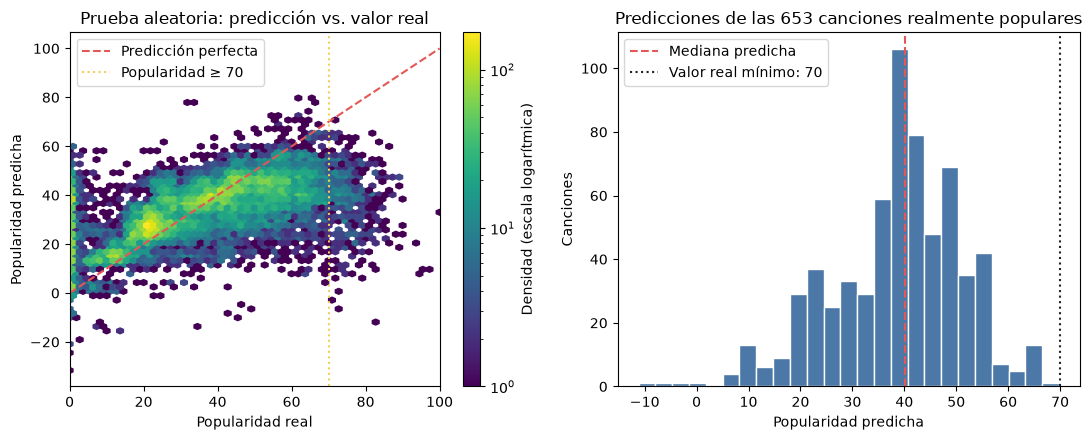

In [7]:
errors["track_id"] = test_data["track_id"].to_numpy()
errors["track_name"] = test_data["track_name"].to_numpy()
errors["artists"] = test_data["artists"].to_numpy()
errors["track_genres"] = test_data["track_genres"].to_numpy()
errors["sesgo"] = errors["predicho"] - errors["actual"]
high = errors.loc[errors["actual"].ge(70)]
extreme = errors.loc[errors["error_absoluto"].ge(40)]
print("Predicciones mínima/máxima:", errors["predicho"].min(), errors["predicho"].max())
print(
    "Predicciones fuera de [0, 100]:",
    errors["predicho"].lt(0).sum(),
    "por debajo de 0 y",
    errors["predicho"].gt(100).sum(),
    "por encima de 100",
)
print("Errores absolutos ≥ 40:", len(extreme), "de", len(errors))
print(
    "Entre ellos, popularidad ≥ 70:",
    extreme["actual"].ge(70).sum(),
    "; popularidad 0:",
    extreme["actual"].eq(0).sum(),
)
print("Canciones ≥ 70 predichas por debajo de 70:", high["predicho"].lt(70).sum(), "de", len(high))
display(
    errors.groupby("rango", sort=False)
    .agg(
        canciones=("actual", "size"),
        real_mediana=("actual", "median"),
        predicho_mediana=("predicho", "median"),
        sesgo_medio=("sesgo", "mean"),
        MAE=("error_absoluto", "mean"),
        error_p90=("error_absoluto", lambda values: values.quantile(0.90)),
    )
    .round(3)
)
display(
    errors.nlargest(10, "error_absoluto")[
        [
            "track_id",
            "track_name",
            "artists",
            "track_genres",
            "actual",
            "predicho",
            "error_absoluto",
        ]
    ].round(2)
)

ranked_errors = errors.sort_values(["predicho", "track_id"], ascending=[False, True])
top_capacity = int(np.ceil(len(errors) * 0.10))
top_errors = ranked_errors.iloc[:top_capacity]
popular_captured = int(top_errors["actual"].ge(70).sum())
print(
    "Ranking de 10%: populares recuperadas / omitidas:",
    popular_captured,
    "/",
    len(high) - popular_captured,
    "; canciones seleccionadas sin llegar a 70:",
    top_capacity - popular_captured,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
density = axes[0].hexbin(
    errors["actual"],
    errors["predicho"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="viridis",
)
axes[0].plot([0, 100], [0, 100], color="#E45756", linestyle="--", label="Predicción perfecta")
axes[0].axvline(70, color="#F2CF5B", linestyle=":", label="Popularidad ≥ 70")
axes[0].set(
    xlim=(0, 100),
    xlabel="Popularidad real",
    ylabel="Popularidad predicha",
    title="Prueba aleatoria: predicción vs. valor real",
)
axes[0].legend(loc="upper left")
fig.colorbar(density, ax=axes[0], label="Densidad (escala logarítmica)")
axes[1].hist(high["predicho"], bins=25, color="#4C78A8", edgecolor="white")
axes[1].axvline(
    high["predicho"].median(), color="#E45756", linestyle="--", label="Mediana predicha"
)
axes[1].axvline(70, color="#222222", linestyle=":", label="Valor real mínimo: 70")
axes[1].set(
    xlabel="Popularidad predicha",
    ylabel="Canciones",
    title=f"Predicciones de las {len(high)} canciones realmente populares",
)
axes[1].legend()
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04b_ignacio_predictions_vs_actual.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

### Lectura del ranking retrospectivo

La tabla compara el ranking de la referencia y de las configuraciones evaluadas en la misma prueba. Interpreta precisión, exhaustividad y *lift* frente a la prevalencia de esta muestra. La lista es una simulación retrospectiva: no representa una decisión de promoción y el valor real de popularidad ya existe en los datos.


## 7. K-Means: perfiles musicales sin usar el objetivo

El agrupamiento usa solo los diez atributos numéricos del entrenamiento y los escala antes de calcular distancias. `popularity`, géneros, IDs y nombres quedan fuera. Se exploran K=2..8 con inercia y silueta sobre una muestra reproducible de 2.000 canciones. La popularidad solo se resume **después** de asignar grupos. La selección considera evidencia cuantitativa, tamaño e interpretabilidad; la sensibilidad se describe sin usar el objetivo para volver a elegir K.


,K,inercia,silueta_muestra,grupo_mínimo_pct
0,2,577883.661,0.245,24.767
1,3,519168.980,0.149,21.412
2,4,474263.881,0.152,7.817
3,5,434429.626,0.168,1.227
4,6,399967.676,0.166,1.209
5,7,369639.701,0.169,1.170
6,8,352524.864,0.176,0.043


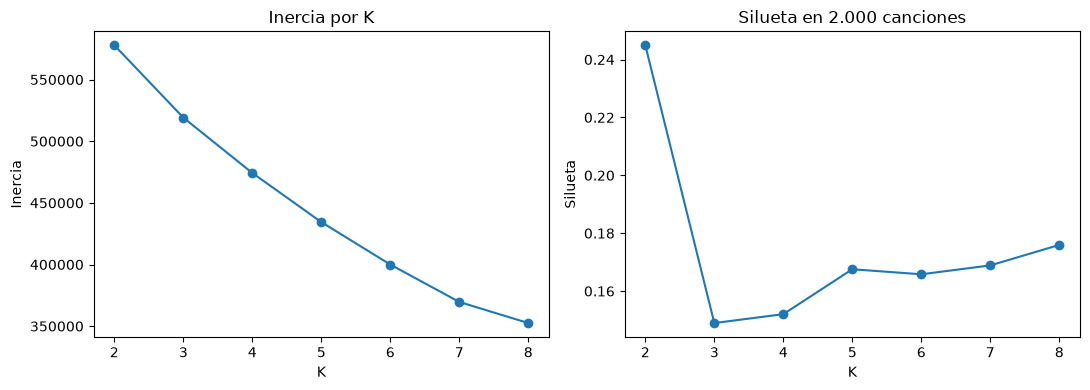

In [8]:
cluster_scaler = StandardScaler().fit(train_data[list(NUMERIC_FEATURES)])
cluster_features = cluster_scaler.transform(train_data[list(NUMERIC_FEATURES)])
sample_indices = np.random.default_rng(SEED).choice(
    len(train_data), size=min(2_000, len(train_data)), replace=False
)
cluster_rows = []
cluster_fits = {}
for k in range(2, 9):
    clustering = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(cluster_features)
    sample_labels = clustering.labels_[sample_indices]
    cluster_rows.append(
        {
            "K": k,
            "inercia": clustering.inertia_,
            "silueta_muestra": silhouette_score(cluster_features[sample_indices], sample_labels),
            "grupo_mínimo_pct": 100 * np.bincount(clustering.labels_).min() / len(train_data),
        }
    )
    cluster_fits[k] = clustering
cluster_evidence = pd.DataFrame(cluster_rows)
display(cluster_evidence.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cluster_evidence["K"], cluster_evidence["inercia"], marker="o")
axes[0].set(title="Inercia por K", xlabel="K", ylabel="Inercia")
axes[1].plot(cluster_evidence["K"], cluster_evidence["silueta_muestra"], marker="o")
axes[1].set(title="Silueta en 2.000 canciones", xlabel="K", ylabel="Silueta")
plt.tight_layout()
plt.show()

La selección de K considera silueta, curva de inercia, tamaño mínimo e interpretabilidad del
perfil. La regla inicial toma el mayor valor de silueta entre soluciones con todos los grupos de al
menos 1% del entrenamiento; tras observar los perfiles se documenta si esa elección produce una
segmentación útil o solo separa extremos. No se usa `popularity` para cambiar K.

K elegido sin consultar popularity: 2


,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularidad_mediana,popularidad_media
cluster,,,,,,,,,,,,,
0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000,34.0,33.919
1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736,29.0,30.794


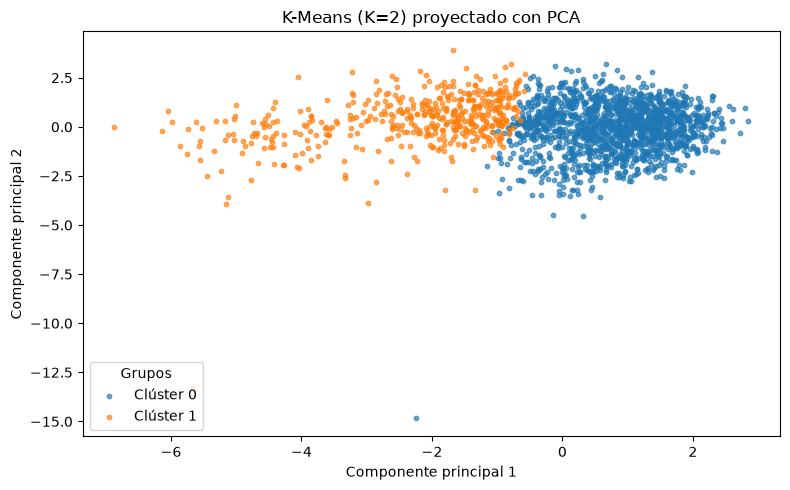

Varianza explicada por PCA: [0.289 0.152] ; suma: 0.441
Figura guardada en: reports\figures\ea2\04b_ignacio_clusters_pca.png


In [9]:
eligible = cluster_evidence.loc[cluster_evidence["grupo_mínimo_pct"].ge(1)]
if eligible.empty:
    eligible = cluster_evidence
chosen_k = int(eligible.sort_values(["silueta_muestra", "K"], ascending=[False, True]).iloc[0]["K"])
chosen_clustering = cluster_fits[chosen_k]
cluster_profile = train_data[list(NUMERIC_FEATURES) + ["popularity"]].copy()
cluster_profile["cluster"] = chosen_clustering.labels_
sizes = cluster_profile.groupby("cluster").size().rename("canciones")
medians = cluster_profile.groupby("cluster")[list(NUMERIC_FEATURES)].median()
posthoc = cluster_profile.groupby("cluster")["popularity"].agg(
    popularidad_mediana="median", popularidad_media="mean"
)
profile = pd.concat([sizes, medians, posthoc], axis=1)
print(f"K elegido sin consultar popularity: {chosen_k}")
display(profile.round(3))

pca = PCA(n_components=2, random_state=SEED).fit(cluster_features)
sample_projection = pca.transform(cluster_features[sample_indices])
fig, ax = plt.subplots(figsize=(8, 5))
for cluster_id in range(chosen_k):
    mask = chosen_clustering.labels_[sample_indices] == cluster_id
    ax.scatter(
        sample_projection[mask, 0],
        sample_projection[mask, 1],
        color=plt.get_cmap("tab10")(cluster_id),
        s=10,
        alpha=0.65,
        label=f"Clúster {cluster_id}",
    )
ax.set(
    xlabel="Componente principal 1",
    ylabel="Componente principal 2",
    title=f"K-Means (K={chosen_k}) proyectado con PCA",
)
ax.legend(title="Grupos", loc="lower left")
plt.tight_layout()
figure_path = PROJECT_PATHS.figures / "ea2" / "04b_ignacio_clusters_pca.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(
    "Varianza explicada por PCA:",
    np.round(pca.explained_variance_ratio_, 3),
    "; suma:",
    round(pca.explained_variance_ratio_.sum(), 3),
)
print("Figura guardada en:", figure_path.relative_to(PROJECT_PATHS.root))

Las dos componentes explican el 44,1 % de la variación de los atributos musicales: la gráfica conserva parte de la información y comprime el resto. Se usa solo para visualizar los clústeres; K-Means se ajustó en el espacio completo de atributos escalados.


### Sensibilidad de K elegido a duración y `loudness`

Se conserva K elegido, la semilla y el conjunto de entrenamiento. Primero se aplica `log1p` únicamente
a `duration_ms` antes de escalar; en un experimento separado se excluye `loudness`, manteniendo
las otras nueve variables. Cada escala y K-Means se reajusta desde cero. Se comparan silueta en
los mismos 2.000 IDs, tamaños y perfiles con medianas en unidades originales. La concordancia se
resume con ARI, que no depende del número arbitrario asignado a cada clúster. Para leer los
perfiles se alinean los nombres de los dos grupos buscando la mayor coincidencia de canciones;
este alineamiento no cambia las asignaciones ni el ARI. No se usa `popularity` para elegir o
ajustar grupos.

In [10]:
baseline_labels = chosen_clustering.labels_
numeric_original = train_data[list(NUMERIC_FEATURES)]
duration_log = numeric_original.copy()
duration_log["duration_ms"] = np.log1p(duration_log["duration_ms"])
without_loudness = numeric_original.drop(columns="loudness")

stability_rows = []
profile_rows = []
for variant, values in (
    ("original", numeric_original),
    ("duración_log1p", duration_log),
    ("sin_loudness", without_loudness),
):
    if variant == "original":
        labels = baseline_labels.copy()
        scaled_values = cluster_features
    else:
        scaled_values = StandardScaler().fit_transform(values)
        labels = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10).fit_predict(
            scaled_values
        )
        if np.mean(labels == baseline_labels) < 0.5:
            labels = 1 - labels
    sizes = np.bincount(labels, minlength=chosen_k)
    stability_rows.append(
        {
            "variante": variant,
            "variables": values.shape[1],
            "silueta_muestra": silhouette_score(
                scaled_values[sample_indices], labels[sample_indices]
            ),
            "ARI_vs_original": adjusted_rand_score(baseline_labels, labels),
            "coincidencia_pct": 100 * np.mean(baseline_labels == labels),
            "grupo_0": int(sizes[0]),
            "grupo_1": int(sizes[1]),
        }
    )
    original_with_group = numeric_original.copy()
    original_with_group["grupo"] = labels
    for group_id, group in original_with_group.groupby("grupo"):
        medians = group[list(NUMERIC_FEATURES)].median()
        profile_rows.append(
            {
                "variante": variant,
                "grupo": int(group_id),
                "canciones": len(group),
                **medians.to_dict(),
            }
        )

stability = pd.DataFrame(stability_rows)
stability_profiles = pd.DataFrame(profile_rows)
display(stability.round(3))
display(stability_profiles.round(3))

,variante,variables,silueta_muestra,ARI_vs_original,coincidencia_pct,grupo_0,grupo_1
0,original,10,0.245,1.000,100.000,54011,17781
1,duración_log1p,10,0.241,0.968,99.258,53954,17838
2,sin_loudness,9,0.209,0.807,95.194,51769,20023


,variante,grupo,canciones,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,original,0,54011,217053.0,0.607,0.762,-6.140,0.055,0.078,0.000,0.145,0.527,125.000
1,original,1,17781,198560.0,0.468,0.295,-13.033,0.039,0.828,0.004,0.116,0.265,107.736
2,duración_log1p,0,53954,217846.5,0.606,0.763,-6.137,0.054,0.077,0.000,0.144,0.525,125.000
3,duración_log1p,1,17838,196084.5,0.469,0.295,-13.014,0.040,0.829,0.004,0.116,0.268,107.598
4,sin_loudness,0,51769,217200.0,0.609,0.775,-6.089,0.056,0.067,0.000,0.147,0.532,125.024
5,sin_loudness,1,20023,200973.0,0.482,0.322,-11.858,0.039,0.804,0.001,0.116,0.287,108.184


### Hipótesis de uso para revisar el catálogo

Los perfiles pueden servir como **estratos de auditoría** del ranking retrospectivo. En una
revisión manual se tomaría una muestra del perfil energético/sonoro y otra del perfil
acústico/tranquilo, y se contaría en cada una cuántas canciones con popularidad ≥ 70 quedaron
fuera del 10% mejor puntuado. Si un perfil concentra omisiones, el equipo podría investigar
variables ausentes —por ejemplo, fecha y exposición— y comprobar la misma pregunta con datos más
representativos antes de cambiar una regla de selección. Esta es una **hipótesis por evaluar**:
el notebook no ha medido aún la cobertura del ranking por clúster. La silueta modesta y los cambios
al quitar `loudness` impiden tratar los grupos como categorías fijas para asignar promoción.

## 8. Interpretación y límites

**Conclusión de esta ejecución.** En validación, Ridge con `alpha=0,1` fue la mejor configuración para los cuatro tratamientos: MAE 11,786 con escalado estándar o robusto y 11,788 con `log1p(duration_ms)`, solo 0,002 puntos de diferencia. En la prueba reservada, ese Ridge obtuvo MAE 11,915 con tratamiento estándar/robusto y 11,914 con `log1p(duration_ms)` (con o sin escalado robusto); el árbol quedó entre 14,507 y 14,508. Por tanto, en esta partición las transformaciones no aportaron una mejora práctica observable. Ridge sí superó a la referencia mediana (MAE 17,250), pero esa diferencia no se puede atribuir a `log1p` o a `RobustScaler`, porque el modelo estándar alcanza esencialmente el mismo resultado. La prueba se usa aquí solo para evaluar las decisiones tomadas con validación; no para escoger una transformación.

Compara primero las configuraciones seleccionadas en validación y luego sus métricas en la prueba reservada. El diseño factorial permite separar el cambio asociado a `log1p(duration_ms)`, el escalado robusto y su combinación. La tabla informa el resultado de prueba del modelo elegido en validación; cualquier mejor modelo observado en prueba se muestra solo de forma descriptiva y no se usa para seleccionar. `RobustScaler` centra por la mediana y escala por el rango intercuartílico, reduciendo la influencia de colas y extremos en la escala sin eliminar observaciones. `log1p(duration_ms)` comprime la cola derecha antes del escalado.

Interpreta MAE, RMSE y R² junto con la referencia mediana y los errores por rango de popularidad. La muestra es histórica y artificialmente balanceada por género; el KPI del 10% es retrospectivo y no demuestra utilidad comercial ni éxito futuro. K-Means describe perfiles exploratorios en atributos musicales y no usa popularidad para formar los grupos.

**Limitación del experimento:** las diferencias corresponden a esta partición y pueden depender de la muestra. Los parámetros se fijan con validación; no se afirma que una transformación sea universalmente superior. El notebook 05 debe reproducir los resultados finales del equipo.
